# Modeling: Predicting Pump Condition

This notebook establishes a reproducible baseline with a preprocessing pipeline and Random Forest. Evaluation pays particular attention to the minority class, `functional needs repair`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = None
for candidate in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
    if (candidate / 'src').is_dir() and (candidate / 'data').is_dir():
        PROJECT_ROOT = candidate
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not locate the project root containing src/ and data/.')
sys.path.insert(0, str(PROJECT_ROOT))

from src.data import load_pump_it_up_data
from src.modeling import (
    build_random_forest_pipeline,
    classification_metrics,
    stratified_split,
)

train_values, train_labels, _ = load_pump_it_up_data(PROJECT_ROOT / 'data')
train = train_values.merge(train_labels, on='id', validate='one_to_one')
X = train.drop(columns=['status_group'])
y = train['status_group']
X_train, X_validation, y_train, y_validation = stratified_split(X, y)
print(f'Train: {X_train.shape}; validation: {X_validation.shape}')

Train: (47520, 40); validation: (11880, 40)


## Reproducible baseline

The pipeline learns imputation and encoding only from the training set. This prevents validation contamination from future information.

In [2]:
baseline = build_random_forest_pipeline(
    X_train,
    n_estimators=50,
    random_state=42,
)
baseline.fit(X_train, y_train)
predictions = baseline.predict(X_validation)
metrics = classification_metrics(y_validation, predictions)

print(f"Accuracy: {metrics['accuracy']:.4f}")
print(f"Macro F1: {metrics['macro_f1']:.4f}")
display(pd.DataFrame(metrics['classification_report']).T.round(3))

Accuracy: 0.8089
Macro F1: 0.6875


,precision,recall,f1-score,support
functional,0.803,0.898,0.847,6452.000
functional needs repair,0.583,0.311,0.405,863.000
non functional,0.844,0.778,0.810,4565.000
accuracy,0.809,0.809,0.809,0.809
macro avg,0.743,0.662,0.687,11880.000
weighted avg,0.803,0.809,0.801,11880.000


## Class-level diagnosis

Accuracy can hide uneven performance across classes. The confusion matrix helps us decide whether recall for pumps that need repair should be prioritized.

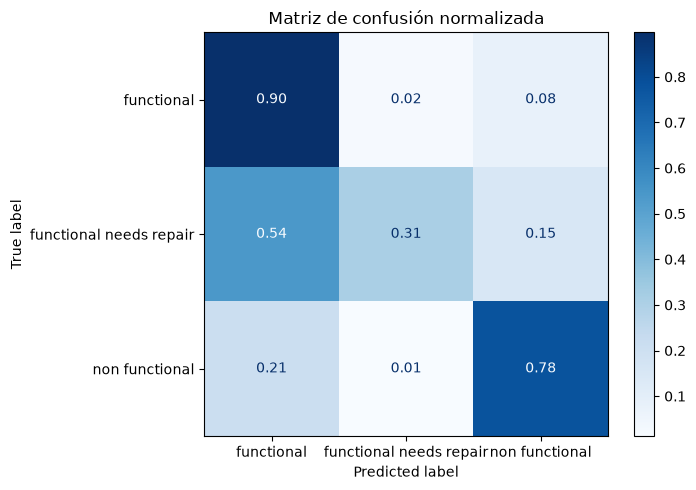

In [3]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(
    y_validation,
    predictions,
    normalize='true',
    cmap='Blues',
    values_format='.2f',
    ax=ax,
)
ax.set_title('Normalized confusion matrix')
plt.tight_layout()
plt.show()

## Next experiment

This baseline will be our reference point. The next experiment will compare `class_weight='balanced'` and other hyperparameters using the same split and metrics, especially macro F1 and recall for `functional needs repair`.